# Example of the aitlas toolbox in the context of multi label image classification

## Import the required packages

In [ ]:
from aitlas.datasets import DLRSDMultilabelDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/dlrsd_multilabel/DLRSD/Images/",
    "csv_file": "./data/dlrsd_multilabel/DLRSD/dlrsd_multilabel_train.csv",
}
dataset = DLRSDMultilabelDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1241


## Show images from the dataset

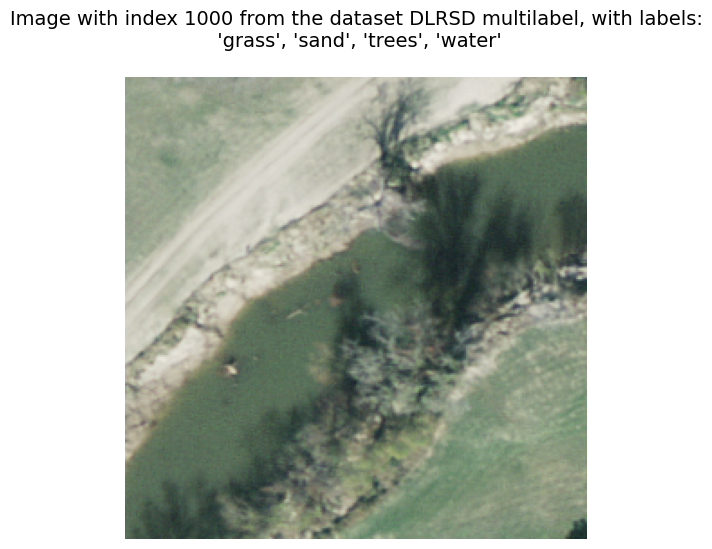

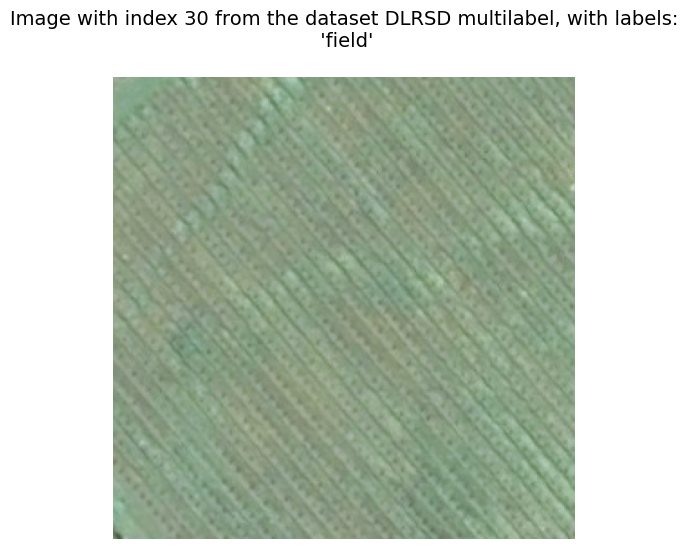

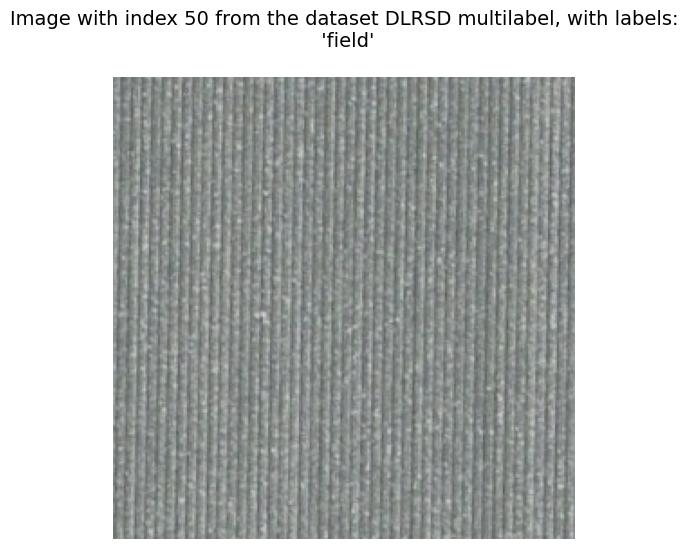

In [5]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)
fig3 = dataset.show_image(50)

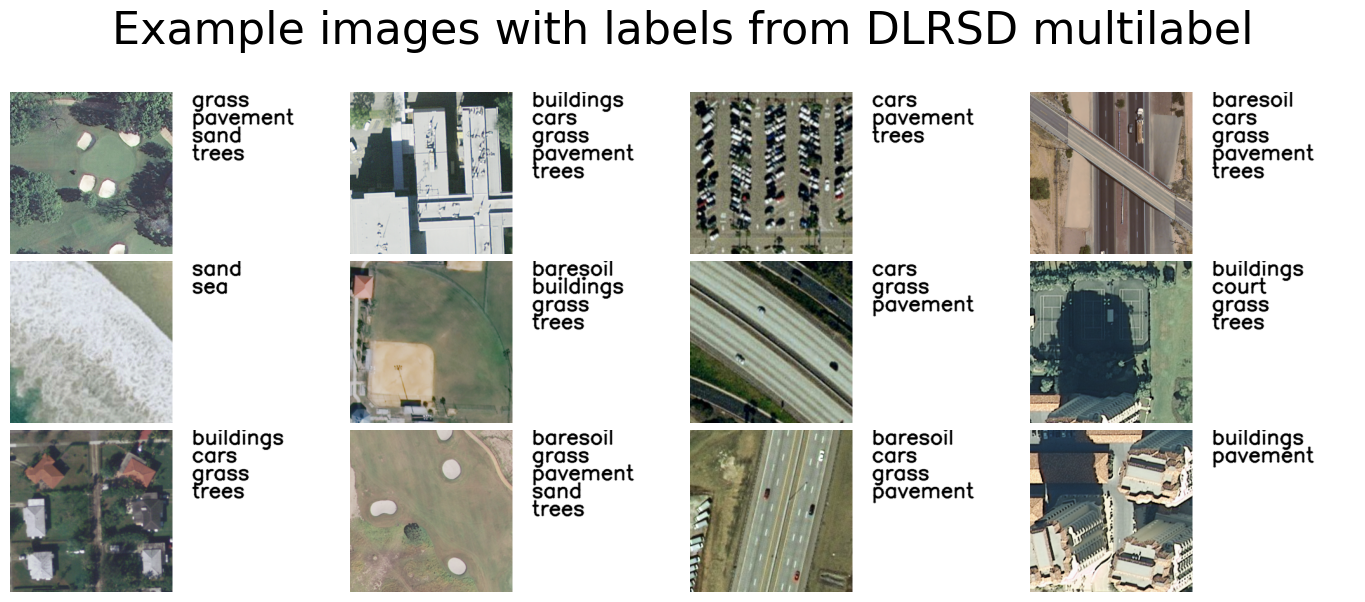

In [6]:
fig4 = dataset.show_batch(12)

## Inspect the data

In [7]:
dataset.show_samples()

,IMAGE\LABEL,airplane,baresoil,buildings,cars,chaparral,court,dock,field,grass,mobilehome,pavement,sand,sea,ship,tanks,trees,water
0,agricultural02,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,agricultural05,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,agricultural08,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,agricultural12,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,agricultural13,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
5,agricultural17,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
6,agricultural19,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
7,agricultural20,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
8,agricultural21,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
9,agricultural23,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


In [8]:
dataset.data_distribution_table()

,Label,Count
1,airplane,60
2,baresoil,452
3,buildings,428
4,cars,538
5,chaparral,70
6,court,63
7,dock,60
8,field,62
9,grass,586
10,mobilehome,61


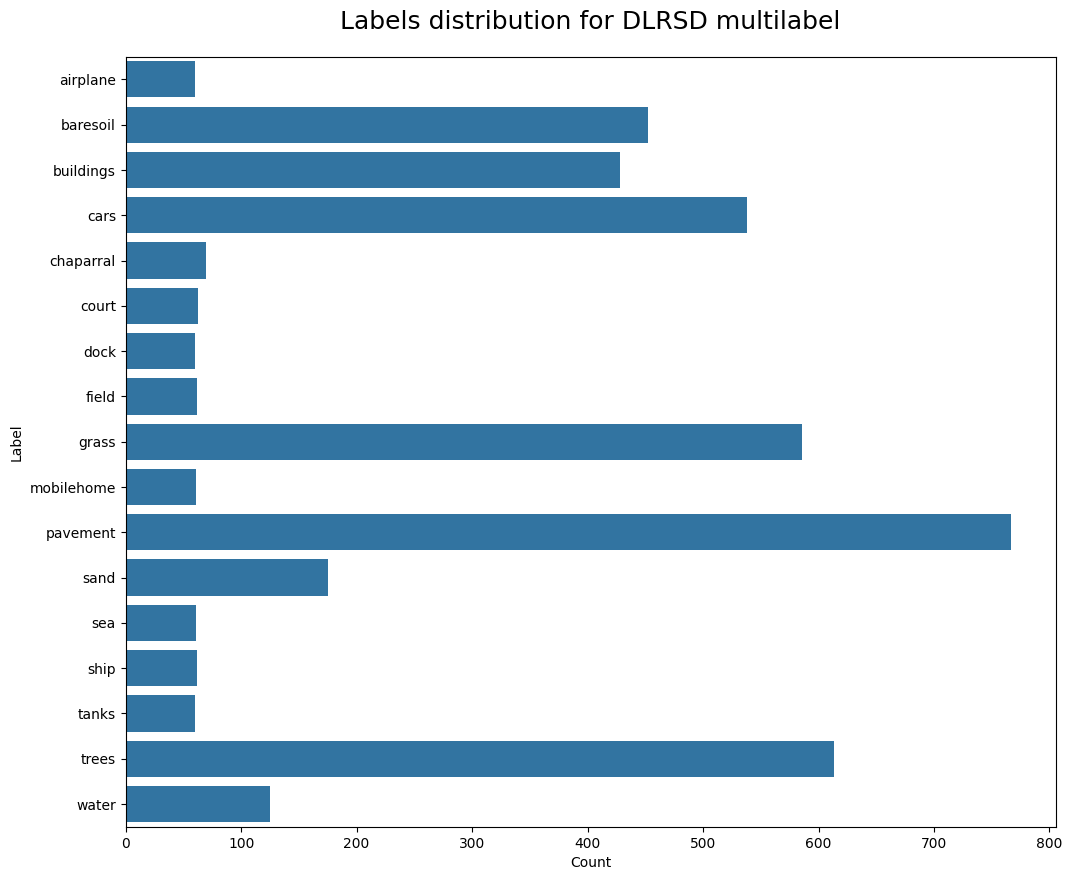

In [9]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/dlrsd_multilabel/DLRSD/Images/",
    "csv_file": "./data/dlrsd_multilabel/DLRSD/dlrsd_multilabel_train.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

train_dataset = DLRSDMultilabelDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor() 

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/dlrsd_multilabel/DLRSD/Images/",
    "csv_file": "./data/dlrsd_multilabel/DLRSD/dlrsd_multilabel_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = DLRSDMultilabelDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(1241, 431)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/dlrsd_multilabel/"
model_config = {
    "num_classes": 17, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5, 
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [12]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id='1',
)

2026-03-30 12:39:58,070 INFO Starting training.
training: 100%|██████████| 78/78 [00:03<00:00, 24.60it/s]
2026-03-30 12:40:01,281 INFO epoch: 1, time: 3, loss:  0.63975
testing on train set: 100%|██████████| 78/78 [00:01<00:00, 62.87it/s]
2026-03-30 12:40:03,083 INFO Accuracy:0.9008863819500403, Accuracy per Class:[0.94842869 0.70668815 0.85092667 0.83078163 0.98952458 0.9540693
 0.96293312 0.99194198 0.7727639  0.95084609 0.8622079  0.92022562
 0.97421434 0.89443997 0.95165189 0.83078163 0.92264303], Precision Micro:0.7574162679425838, Precision Macro:0.6933934763425887, Precision Weighted:0.7699777828185237, Precision per Class:[0.46       0.90740741 0.72541744 0.74550898 0.95238095 0.625
 1.         0.96428571 0.71111111 0.         0.83111111 0.72352941
 1.         0.31746032 0.         0.82447665 1.        ], Recall Micro:0.7461701626207872, Recall Macro:0.5706519045185383, Recall Weighted:0.7461701626207872, Recall per Class:[0.38333333 0.21681416 0.9135514  0.92565056 0.85714286 

0.06557212108280258

## Predictions

2026-03-30 12:49:57,327 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/dlrsd_multilabel/checkpoint.pth.tar
2026-03-30 12:49:57,540 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/dlrsd_multilabel/checkpoint.pth.tar at epoch 11


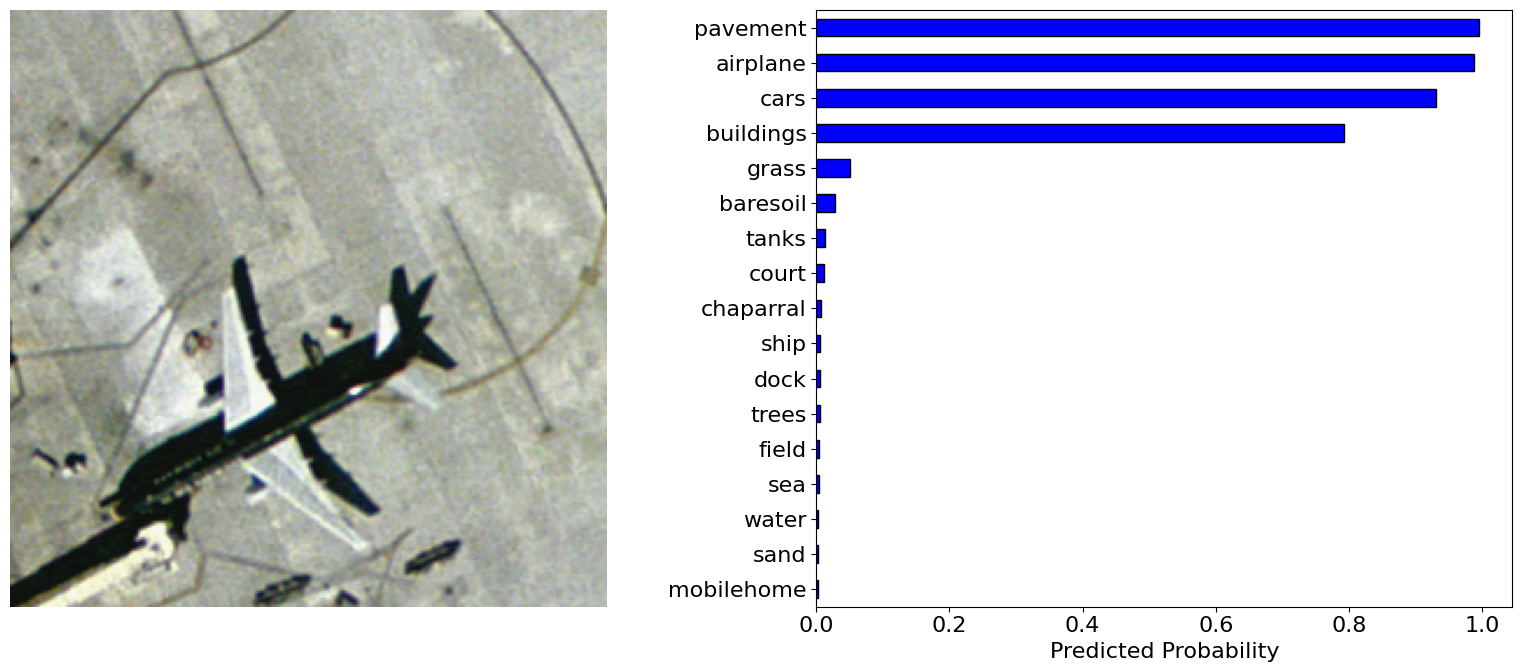

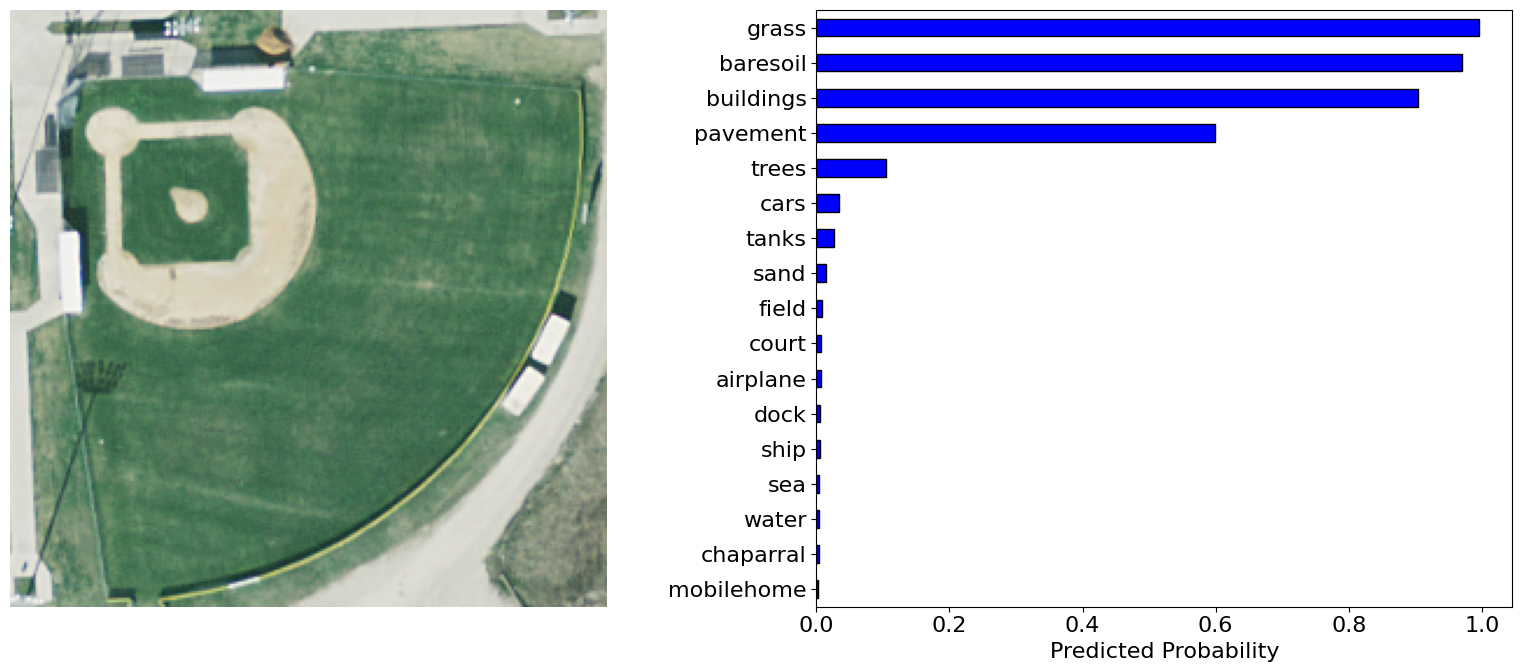

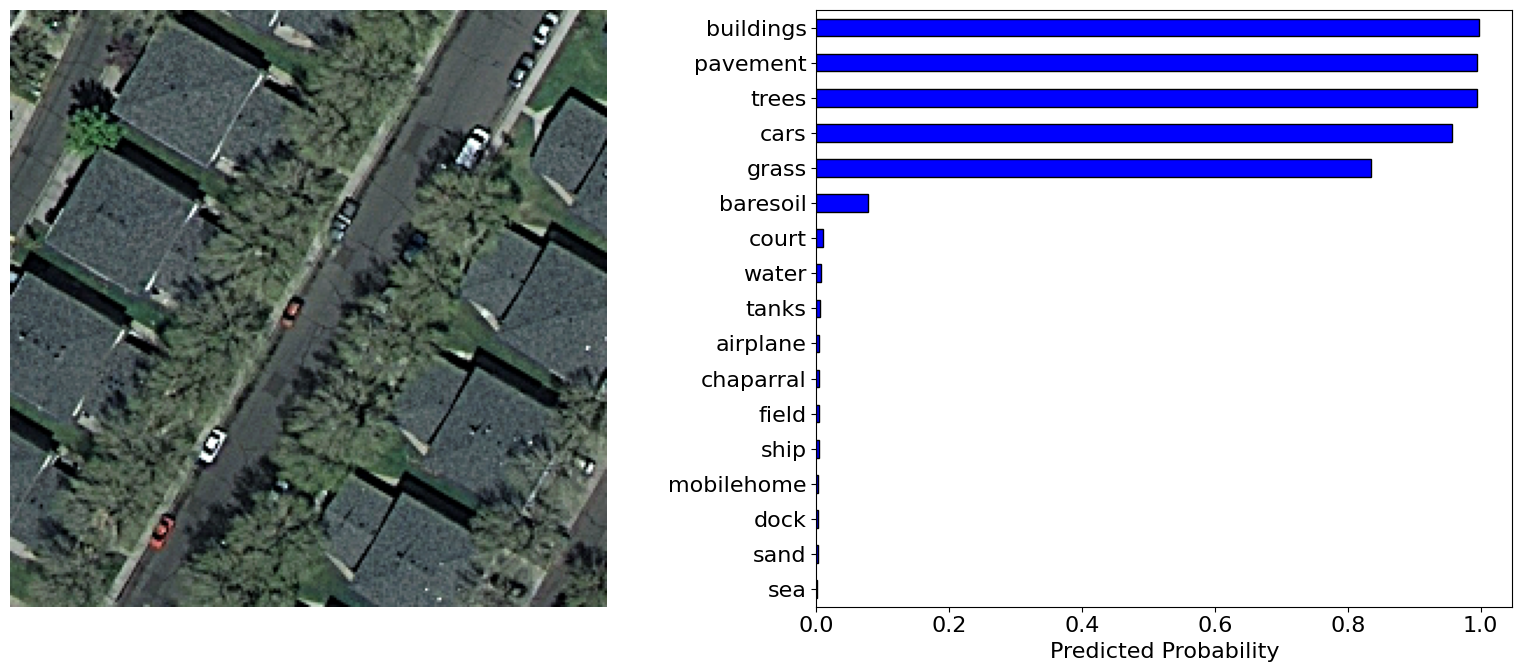

In [ ]:
model_path = "./data/experiments/dlrsd_multilabel/checkpoint.pth.tar"
labels = ["airplane","baresoil","buildings","cars","chaparral","court","dock","field","grass","mobilehome","pavement","sand","sea","ship","tanks","trees","water"]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

image = image_loader('./data/dlrsd_multilabel/DLRSD/Images/airplane/airplane52.tif')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/dlrsd_multilabel/DLRSD/Images/baseballdiamond/baseballdiamond50.tif')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/dlrsd_multilabel/DLRSD/Images/denseresidential/denseresidential83.tif')
fig = model.predict_image(image, labels, transform)